In [1]:
import torch
import transformers

STUDENT_NAME = "Wayne Wang"
print("Name:", STUDENT_NAME)
print("torch version:", torch.__version__)
print("transformers version:", transformers.__version__)

Name: Wayne Wang
torch version: 2.15.0
transformers version: 5.22.2


# CSE 256 PA2, Part 3: Dissecting a Pretrained LLM

Model: `EleutherAI/pythia-160m-deduped` (12 layers, 12 heads, d = 768), at checkpoints `step0`, `step512`, `step1000`, `step8000`, `step32000` and `step143000`.

Only `transformers` is used, and only to load the tokenizer and the checkpoints. The lens readouts and the transplants are written below by hand.

## Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from transformers import AutoTokenizer, GPTNeoXForCausalLM

MODEL_NAME = "EleutherAI/pythia-160m-deduped"
FINAL_STEP = "step143000"
TEST_PATH = "speechesdataset/test_LM_obama.txt"
WINDOW = 512

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
tok = AutoTokenizer.from_pretrained(MODEL_NAME)


def load_checkpoint(step):
    model = GPTNeoXForCausalLM.from_pretrained(MODEL_NAME, revision=step, torch_dtype=torch.float32)
    return model.to(device).eval()


with open(TEST_PATH, encoding="utf-8") as f:
    test_text = f.read()
test_ids = tok(test_text, return_tensors="pt").input_ids.to(device)
test_windows = test_ids.split(WINDOW, dim=1)
n_predicted = sum(w.shape[1] - 1 for w in test_windows)
print("device:", device)
print("tokens in test_LM_obama.txt:", test_ids.shape[1])
print(f"windows of up to {WINDOW} tokens:", len(test_windows))
print("next-token predictions scored:", n_predicted)

final_model = load_checkpoint(FINAL_STEP)

W1113 00:23:39.645000 93105 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: cpu
tokens in test_LM_obama.txt: 6017
windows of up to 512 tokens: 12
next-token predictions scored: 6005


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

**How the test file is fed to the model.** The whole of `test_LM_obama.txt` is tokenized once with the Pythia tokenizer and cut into consecutive, non-overlapping windows of 512 tokens (the last one is shorter). Inside each window, every position except the last has a true next token, and those are the predictions that are scored. The same windows are used for the lens accuracy in 3.2 and for the test loss in 3.3, so the numbers are comparable across sections.

## 3.1 Reading Pythia

### 3.1.1 Why checkpoints?


The design has two parts: 154 saved checkpoints per model (§2.4: one at initialization, one every 1,000 steps, plus ten log-spaced early ones at steps 1, 2, 4, ..., 512), and one fixed, reconstructable data order shared by every model size (§1 and §2.1), so each checkpoint can be linked to exactly the data it had seen.

**Depends on it most: the gender-bias study (§3.1).** The authors resume from a checkpoint (with its optimizer state) 7% or 21% before the end of training and replay the *same* remaining data, changed only by swapping masculine pronouns for feminine ones. That is a controlled counterfactual: the only difference from the released model is the edited data. It needs both parts of the design at once, an intermediate checkpoint to restart from and the exact data order to replay. With only a final model there is nothing to resume and nothing to compare against. The term-frequency study (§3.3) is a close second: it evaluates many checkpoints and counts how often each term appeared in the data seen *up to that checkpoint*, which also needs both parts.

**Mostly doable with the final model: the memorization study (§3.2).** It asks whether a sequence's position in the training order affects whether it is memorized, by prompting a trained model with 32 tokens of a training sequence and checking whether it reproduces the next 32, then fitting a Poisson model to the count of memorized sequences per batch in training order. What this needs from the design is the known data order (to say where in training each sequence was seen), not the intermediate weights. So it still depends on the "same, known order" half of the design, but the measurement itself can be made on a fully trained model.

### 3.1.2 Data


**Finding (§2.6, "Novel Observations in Evaluation"):** deduplicating the training data gave *no clear benefit* to language-modeling performance. The deduped and non-deduped models of the same size score about the same on the paper's evaluations. This goes against the common advice that motivated the deduplicated copy in the first place (§2.2: models trained on deduplicated data were expected to be better and to memorize less). The authors offer two possible reasons in §2.6: the Pile upsamples some of its subsets, which may break the usual assumptions about duplicated data, or the benefit other work attributes to deduplication may really come from higher data quality.

A related detail from §2.4: both versions are trained on the same number of tokens, so the deduped models, whose dataset is smaller (about 207B tokens, §2.2), go through it about 1.5 times, and the authors report no sign that the second pass hurts evaluation scores.

## 3.2 The Logit Lens

The lens readout at layer $\ell$ is $W_U\,\mathrm{LN}_f(h_\ell)$. The first thing to settle is the hint from the handout: does the last entry of `out.hidden_states` already have $\mathrm{LN}_f$ applied?

In [3]:
@torch.no_grad()
def check_final_layer_norm(model, ids):
    out = model(ids, output_hidden_states=True)
    unembed = model.get_output_embeddings()
    ln_f = model.gpt_neox.final_layer_norm
    last = out.hidden_states[-1]
    without_ln = (unembed(last) - out.logits).abs().max().item()
    with_ln = (unembed(ln_f(last)) - out.logits).abs().max().item()
    return len(out.hidden_states), without_ln, with_ln


n_states, without_ln, with_ln = check_final_layer_norm(final_model, test_windows[0][:, :64])
print("entries in out.hidden_states:", n_states)
print(f"max |W_U h_last        - out.logits| = {without_ln:.6f}")
print(f"max |W_U LN_f(h_last)  - out.logits| = {with_ln:.6f}")
LAST_STATE_HAS_LN_F = without_ln < 1e-3
print("last hidden state already has LN_f applied:", LAST_STATE_HAS_LN_F)

entries in out.hidden_states: 13
max |W_U h_last        - out.logits| = 0.000000
max |W_U LN_f(h_last)  - out.logits| = 17.086365
last hidden state already has LN_f applied: True


**Result of the check.** `out.hidden_states` has 13 entries (embeddings + 12 layers). In this version of `transformers` the last entry **already has $\mathrm{LN}_f$ applied**: unembedding it directly reproduces `out.logits` exactly (max difference 0.000000), while applying $\mathrm{LN}_f$ a second time is off by up to 17.09 logits. So below, layers 0 to 11 are read as $W_U\,\mathrm{LN}_f(h_\ell)$ and layer 12 is read as $W_U$ applied to the last entry. The flag `LAST_STATE_HAS_LN_F` is computed, not assumed, and `lens_readouts` asserts on every call that its top readout equals the model's real output.

In [4]:
@torch.no_grad()
def lens_readouts(model, ids):
    """Yields (layer, logits of shape (T, V)) for layer = 0 (embeddings), 1, ..., 12.

    Layer l < 12 is read as W_U LN_f(h_l). The last hidden state is read with or
    without LN_f according to the check above, and must reproduce out.logits."""
    out = model(ids, output_hidden_states=True)
    unembed = model.get_output_embeddings()
    ln_f = model.gpt_neox.final_layer_norm
    states = out.hidden_states
    for layer, h in enumerate(states[:-1]):
        yield layer, unembed(ln_f(h))[0]
    top = unembed(states[-1] if LAST_STATE_HAS_LN_F else ln_f(states[-1]))[0]
    assert torch.allclose(top, out.logits[0], atol=1e-3), "top lens readout must equal the model output"
    yield len(states) - 1, top


def show_token(token_id):
    text = tok.decode([token_id]).replace(" ", "_").replace("\n", "\\n")
    text = text.encode("ascii", "backslashreplace").decode("ascii").replace("$", r"\$")
    return text if len(text) <= 9 else text[:8] + "~"


@torch.no_grad()
def lens_grid(model, sentence):
    """Top-1 token and probability of the true next token, per layer and position."""
    ids = tok(sentence, return_tensors="pt").input_ids.to(device)
    targets = ids[0, 1:]
    top_tokens, true_probs = [], []
    for _, logits in lens_readouts(model, ids):
        probs = logits.softmax(dim=-1)
        top_tokens.append(probs.argmax(dim=-1).tolist())
        row = torch.full((ids.shape[1],), float("nan"))
        row[:-1] = probs[:-1].gather(1, targets[:, None])[:, 0].cpu()
        true_probs.append(row)
    return ids[0].tolist(), top_tokens, torch.stack(true_probs).numpy()


def plot_lens_grid(model, sentence, step):
    ids, top_tokens, true_probs = lens_grid(model, sentence)
    n_layers, n_pos = true_probs.shape
    fig, ax = plt.subplots(figsize=(0.8 * n_pos + 1.5, 0.45 * n_layers + 1.6))
    cmap = plt.get_cmap("RdPu").copy()
    cmap.set_bad("#e6e6e6")
    image = ax.imshow(np.ma.masked_invalid(true_probs), cmap=cmap, vmin=0, vmax=1, aspect="auto", origin="lower")
    for layer in range(n_layers):
        for pos in range(n_pos):
            p = true_probs[layer, pos]
            ax.text(pos, layer, show_token(top_tokens[layer][pos]), ha="center", va="center", fontsize=8.5,
                    color="white" if p > 0.6 else "black")
    ax.set_xticks(range(n_pos), [show_token(i) for i in ids], fontsize=9)
    ax.set_yticks(range(n_layers), ["emb (0)"] + [str(l) for l in range(1, n_layers)])
    ax.set_xlabel("input token (the cell above it shows the lens's top-1 guess for the NEXT token)")
    ax.set_ylabel("layer $\\ell$")
    ax.set_title(f"Logit lens at {step}: \"{sentence}\"\n"
                 "cell text = top token of $W_U\\,LN_f(h_\\ell)$; shade = probability of the true next token "
                 "(grey = last position, no next token)", fontsize=9)
    fig.colorbar(image, ax=ax, label="P(true next token)", pad=0.01)
    plt.tight_layout()
    plt.show()
    print("true next tokens: ", [show_token(i) for i in ids[1:]])
    print("top-1 at layer 12:", [show_token(i) for i in top_tokens[-1]])
    print("P(true next token), rows = layers 12 down to 0, columns = input positions:")
    for layer in range(n_layers - 1, -1, -1):
        print(f"  layer {layer:2d}: " + " ".join(f"{p:.3f}" for p in true_probs[layer, :-1]))

### 3.2.1 Watch a prediction form

**Sentence (i)**, from `test_LM_obama.txt`: "They have not served a Red America or a Blue America".

tokens: 11


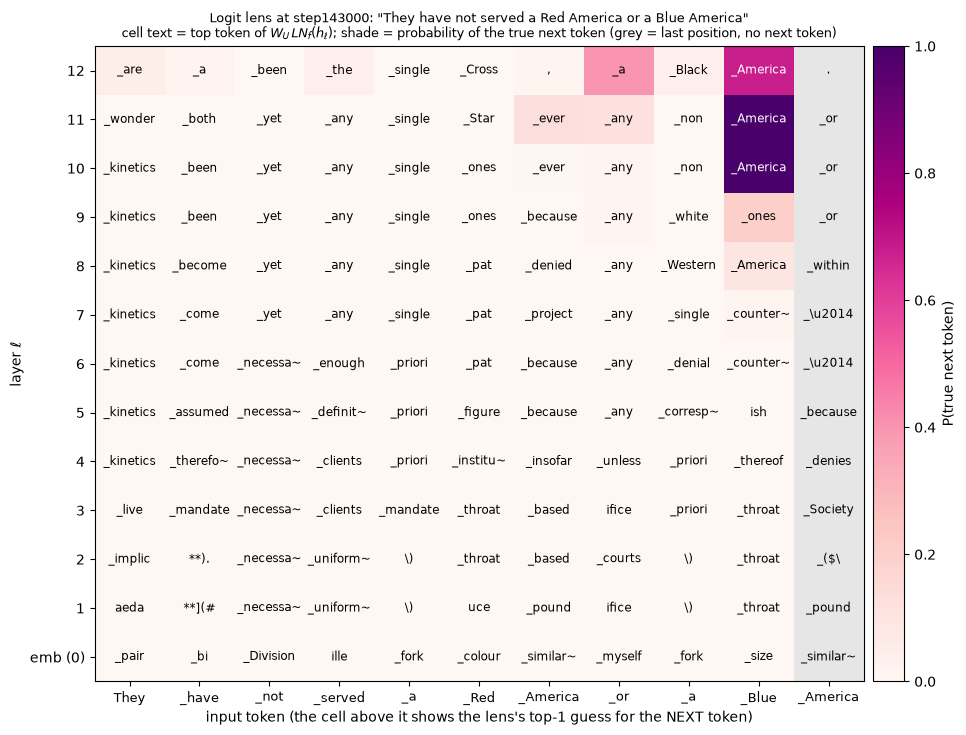

true next tokens:  ['_have', '_not', '_served', '_a', '_Red', '_America', '_or', '_a', '_Blue', '_America']
top-1 at layer 12: ['_are', '_a', '_been', '_the', '_single', '_Cross', ',', '_a', '_Black', '_America', '.']
P(true next token), rows = layers 12 down to 0, columns = input positions:
  layer 12: 0.047 0.022 0.001 0.041 0.000 0.000 0.016 0.396 0.042 0.677
  layer 11: 0.000 0.000 0.000 0.000 0.000 0.000 0.127 0.120 0.001 0.994
  layer 10: 0.000 0.001 0.000 0.000 0.000 0.000 0.005 0.010 0.001 0.997
  layer  9: 0.000 0.000 0.000 0.000 0.000 0.000 0.002 0.010 0.000 0.201
  layer  8: 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.097
  layer  7: 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.012
  layer  6: 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000
  layer  5: 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000
  layer  4: 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000
  layer  3: 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000

In [5]:
SENTENCE_OBAMA = "They have not served a Red America or a Blue America"
assert SENTENCE_OBAMA in test_text
print("tokens:", len(tok(SENTENCE_OBAMA).input_ids))
plot_lens_grid(final_model, SENTENCE_OBAMA, FINAL_STEP)

**Sentence (ii)**, my own.

tokens: 14


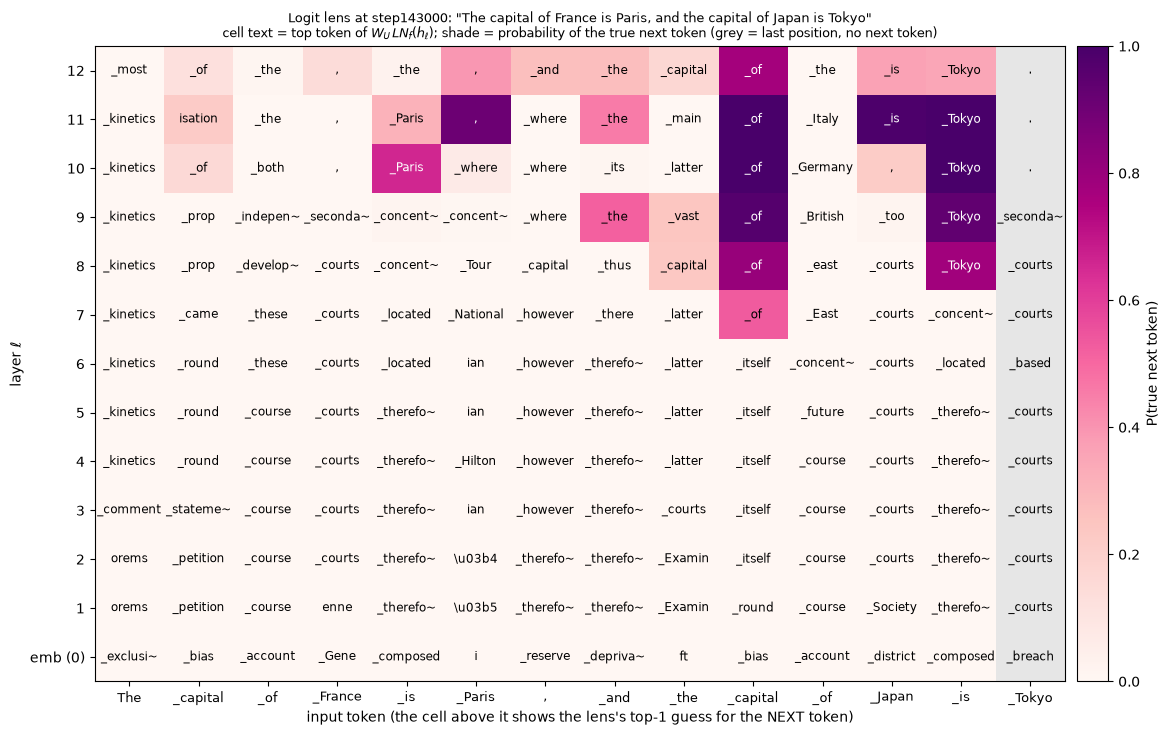

true next tokens:  ['_capital', '_of', '_France', '_is', '_Paris', ',', '_and', '_the', '_capital', '_of', '_Japan', '_is', '_Tokyo']
top-1 at layer 12: ['_most', '_of', '_the', ',', '_the', ',', '_and', '_the', '_capital', '_of', '_the', '_is', '_Tokyo', '.']
P(true next token), rows = layers 12 down to 0, columns = input positions:
  layer 12: 0.000 0.124 0.008 0.143 0.025 0.392 0.269 0.272 0.164 0.770 0.001 0.366 0.350
  layer 11: 0.000 0.219 0.000 0.004 0.310 0.907 0.000 0.455 0.001 1.000 0.000 0.987 0.999
  layer 10: 0.000 0.156 0.000 0.000 0.660 0.069 0.000 0.010 0.000 1.000 0.000 0.217 0.999
  layer  9: 0.000 0.002 0.000 0.000 0.013 0.006 0.000 0.519 0.243 0.966 0.000 0.012 0.937
  layer  8: 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.237 0.804 0.000 0.001 0.779
  layer  7: 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.529 0.000 0.000 0.000
  layer  6: 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.001 0.000 0.000 0.000
  layer  5: 0.000 0.000 0.000 0.00

In [6]:
SENTENCE_OWN = "The capital of France is Paris, and the capital of Japan is Tokyo"
print("tokens:", len(tok(SENTENCE_OWN).input_ids))
plot_lens_grid(final_model, SENTENCE_OWN, FINAL_STEP)

**What the two grids show** (all numbers are from the probability tables printed under each grid).

*In the bottom half of the network the lens does not find the next word.* In both sentences the probability of the true next token is 0.000 at every position for layers 0 to 6 (the single exception is 0.001 at one position of layer 6 in sentence ii). The top tokens there (`_kinetics`, `_necessa~`, `_priori`, `_courts`, `_therefo~`) have no visible relation to the sentence, and several repeat across positions and layers.

*Predictions appear late and in order of difficulty.*
- Sentence (i), "... a Blue" → `_America`: 0.012 at layer 7, 0.097 at layer 8, 0.201 at layer 9, then 0.997 at layer 10. This is the one word that the context makes predictable, because "a Red America or a Blue ..." repeats an earlier phrase. The *first* `_America` (after "Red") cannot be guessed and gets 0.000 at every layer; the model's real output there is `_Cross`.
- Sentence (ii), second "of" (after the second "capital"): 0.529 at layer 7 and 1.000 by layer 10. `_Tokyo` after "Japan is": 0.000 at layer 7, 0.779 at layer 8, 0.999 at layers 10 and 11. `_Paris` after "France is" shows up later, 0.013 at layer 9 and 0.660 at layer 10. At the Tokyo position the sentence already contains a pattern to copy ("the capital of France is Paris"), and the correct word appears two layers earlier than at the Paris position, where there is no such pattern.

*The last layer lowers some probabilities as well as raising others.* Lens probabilities at layers 10 and 11 are often far higher than the model's actual output: `_Tokyo` 0.999 → 0.350, `_America` 0.994 → 0.677, second `_of` 1.000 → 0.770. For `_Paris` the top-1 token at layers 10 and 11 is `_Paris`, but the real output gives it only 0.025 and puts `_the` on top. In the other direction, some predictions of function words appear only at layer 12: `_and` after the comma goes from 0.000 at layer 11 to 0.269, and `_a` after "or" in sentence (i) from 0.120 to 0.396. So the last layer changes the distribution a lot in both directions, and a lens readout one layer below the top is not yet the model's answer.

Overall the real output (layer 12) has the right top-1 token at 2 of 10 positions in sentence (i) and 8 of 13 in sentence (ii), which is a much more predictable sentence.

**Top-1 accuracy of the lens over the whole of `test_LM_obama.txt`, at the final checkpoint.**

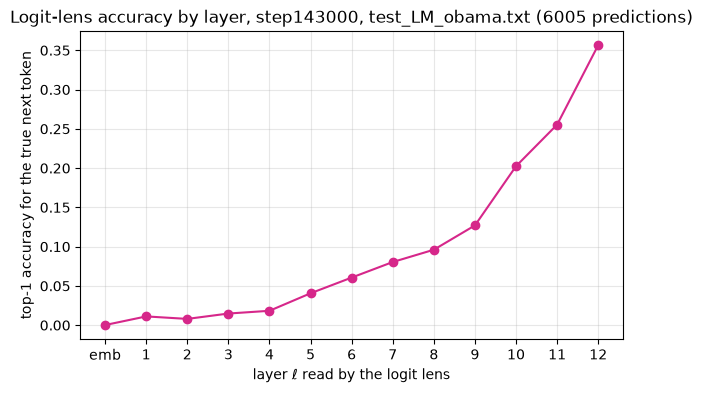

layer  0: accuracy = 0.000167
layer  1: accuracy = 0.011157
layer  2: accuracy = 0.007993
layer  3: accuracy = 0.014821
layer  4: accuracy = 0.018318
layer  5: accuracy = 0.040633
layer  6: accuracy = 0.060616
layer  7: accuracy = 0.080433
layer  8: accuracy = 0.096087
layer  9: accuracy = 0.127061
layer 10: accuracy = 0.202498
layer 11: accuracy = 0.255454
layer 12: accuracy = 0.356703

EXACT top-1 accuracy at layer  0 (step143000): np.float64(0.00016652789342214822)
EXACT top-1 accuracy at layer  6 (step143000): np.float64(0.06061615320566195)
EXACT top-1 accuracy at layer 12 (step143000): np.float64(0.35670274771024146)


In [7]:
@torch.no_grad()
def lens_accuracy_by_layer(model):
    """Fraction of scored positions where the lens's top-1 token is the true next token, for l = 0..12."""
    correct = None
    for window in test_windows:
        targets = window[0, 1:]
        hits = [(logits[:-1].argmax(dim=-1) == targets).sum().item() for _, logits in lens_readouts(model, window)]
        correct = np.array(hits) if correct is None else correct + np.array(hits)
    return correct / n_predicted


accuracy = {FINAL_STEP: lens_accuracy_by_layer(final_model)}
layers = np.arange(len(accuracy[FINAL_STEP]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(layers, accuracy[FINAL_STEP], marker="o", color="#d6278a")
ax.set_xticks(layers, ["emb"] + [str(l) for l in layers[1:]])
ax.set_xlabel("layer $\\ell$ read by the logit lens")
ax.set_ylabel("top-1 accuracy for the true next token")
ax.set_title(f"Logit-lens accuracy by layer, {FINAL_STEP}, test_LM_obama.txt ({n_predicted} predictions)")
ax.grid(alpha=0.3)
plt.show()

for layer in layers:
    print(f"layer {layer:2d}: accuracy = {accuracy[FINAL_STEP][layer]:.6f}")
print()
for layer in (0, 6, 12):
    print(f"EXACT top-1 accuracy at layer {layer:2d} ({FINAL_STEP}): {accuracy[FINAL_STEP][layer]!r}")

**Reading the curve.** At the final checkpoint the lens goes from 0.000167 at layer 0 (1 of 6005 predictions correct) to 0.0606 at layer 6 and 0.3567 at layer 12. The rise is not even: layer 6, halfway up the network, has only 17% of the final accuracy (0.0606 / 0.3567), and the last three layers add 0.230 of the 0.357 (from 0.1271 at layer 9). It is also not strictly monotone at the bottom (0.0112 at layer 1, 0.0080 at layer 2). This matches the grids above: read through $W_U\,\mathrm{LN}_f$, the lower and middle layers of the fully trained model give almost no correct predictions.

### 3.2.2 Across training

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

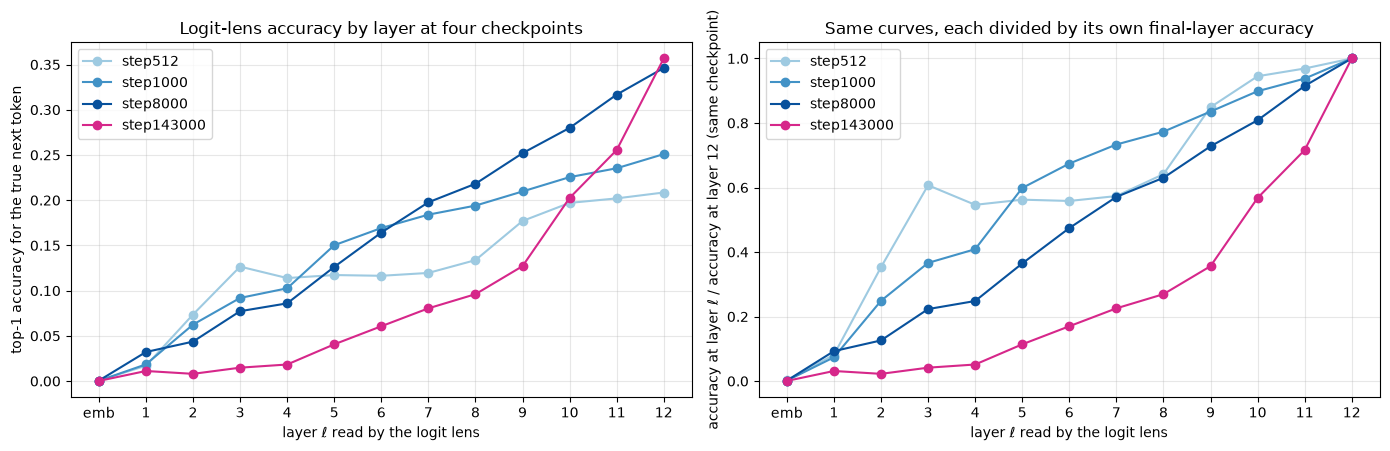

top-1 accuracy by layer
layer     step512    step1000    step8000  step143000
    0      0.0005      0.0003      0.0005      0.0002
    1      0.0170      0.0185      0.0321      0.0112
    2      0.0736      0.0624      0.0436      0.0080
    3      0.1266      0.0919      0.0773      0.0148
    4      0.1139      0.1026      0.0859      0.0183
    5      0.1172      0.1502      0.1262      0.0406
    6      0.1164      0.1692      0.1642      0.0606
    7      0.1196      0.1840      0.1977      0.0804
    8      0.1337      0.1940      0.2182      0.0961
    9      0.1770      0.2097      0.2520      0.1271
   10      0.1970      0.2255      0.2799      0.2025
   11      0.2020      0.2353      0.3167      0.2555
   12      0.2085      0.2510      0.3462      0.3567

accuracy at layer l divided by accuracy at layer 12
    0      0.0024      0.0013      0.0014      0.0005
    1      0.0815      0.0737      0.0928      0.0313
    2      0.3530      0.2488      0.1260      0.0224
    3

In [8]:
LENS_STEPS = ["step512", "step1000", "step8000", "step143000"]
for step in LENS_STEPS:
    if step not in accuracy:
        accuracy[step] = lens_accuracy_by_layer(load_checkpoint(step))

colors = dict(zip(LENS_STEPS, ["#9ecae1", "#4292c6", "#08519c", "#d6278a"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for step in LENS_STEPS:
    axes[0].plot(layers, accuracy[step], marker="o", label=step, color=colors[step])
    axes[1].plot(layers, accuracy[step] / accuracy[step][-1], marker="o", label=step, color=colors[step])
axes[0].set_ylabel("top-1 accuracy for the true next token")
axes[0].set_title("Logit-lens accuracy by layer at four checkpoints")
axes[1].set_ylabel("accuracy at layer $\\ell$ / accuracy at layer 12 (same checkpoint)")
axes[1].set_title("Same curves, each divided by its own final-layer accuracy")
for ax in axes:
    ax.set_xticks(layers, ["emb"] + [str(l) for l in layers[1:]])
    ax.set_xlabel("layer $\\ell$ read by the logit lens")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

print("top-1 accuracy by layer")
print("layer  " + "  ".join(f"{step:>10s}" for step in LENS_STEPS))
for layer in layers:
    print(f"{layer:5d}  " + "  ".join(f"{accuracy[step][layer]:10.4f}" for step in LENS_STEPS))
print()
print("accuracy at layer l divided by accuracy at layer 12")
for layer in layers:
    print(f"{layer:5d}  " + "  ".join(f"{accuracy[step][layer] / accuracy[step][-1]:10.4f}" for step in LENS_STEPS))
print()
middle = slice(4, 9)
for step in LENS_STEPS:
    print(f"{step:>10s}: mean accuracy over middle layers 4-8 = {accuracy[step][middle].mean():.4f}, "
          f"as a fraction of layer 12 = {accuracy[step][middle].mean() / accuracy[step][-1]:.4f}")

**Do the middle layers become more or less readable as training goes on? Less.**

Taking layers 4 to 8 as "the middle" (numbers from the printout above):

| checkpoint | layer 12 (real output) | mean of layers 4–8 | middle as a fraction of layer 12 |
|---|---|---|---|
| step512 | 0.2085 | 0.1202 | 0.576 |
| step1000 | 0.2510 | 0.1600 | 0.638 |
| step8000 | 0.3462 | 0.1584 | 0.458 |
| step143000 | 0.3567 | 0.0592 | 0.166 |

- In absolute terms the middle goes up slightly at the very start (0.120 → 0.160 between step512 and step1000, when the whole model is still improving fast), stays flat to step8000 (0.158), and then falls to 0.059. The final model's middle layers are *less than half as readable as they were at step512*, even though its real output is far better (0.357 against 0.209).
- Relative to each checkpoint's own output, the trend from step1000 on is one-directional: 0.638 → 0.458 → 0.166. In the right-hand plot, each later checkpoint's curve lies lower in the middle layers.
- The clearest piece of evidence is the last interval. Between step8000 and step143000 the output accuracy barely moves (0.3462 → 0.3567), but layer 6 drops from 0.1642 to 0.0606 and layer 3 from 0.0773 to 0.0148. The model kept reorganizing its internal representation long after its top-1 accuracy on this text had stopped improving.
- The shape of the curve changes accordingly. At step512, layer 3 already has 61% of the final accuracy (0.1266 / 0.2085) and the last three layers add little. At step143000, layer 3 has 4% and the last three layers add 64% (0.230 of 0.357).

**What this suggests about the "language" of the middle layers.** The logit lens assumes that every layer writes in the coordinates that $W_U\,\mathrm{LN}_f$ reads. My curves say this is roughly true early in training and becomes less true the longer the model trains. Early on, each layer makes a small correction to something that is already close to an output distribution, so reading any layer with the output head works. In the trained model the middle layers use their own coordinates, and the last few layers convert them into output coordinates. The accuracy appears in those last layers.

Low lens accuracy therefore does not mean the middle layers carry no information about the next token. Section 3.3 below shows the opposite: replacing a single middle layer of the final model costs between 0.3 and 3.7 nats per token, so those layers do work that the lens cannot read. The lens fails because it reads those layers in the wrong coordinates, not because the layers contain nothing. The tuned lens of Belrose et al. is designed for this problem: it learns a separate affine map for each layer that takes $h_\ell$ into the output basis before unembedding, instead of assuming the basis is shared. I did not train a tuned lens here, so I cannot say how much of the gap it would close on this text; what my results show is that the gap exists and that it grows during training.

## 3.3 Transplanting Layers Across Time

The recipient is always the intact final model (`step143000`). One component at a time (the embedding `embed_in`, one of the 12 layers, or the unembedding matrix) is overwritten with the same component from a donor checkpoint, the test loss on `test_LM_obama.txt` is measured, and the original weights are put back before the next transplant. The final layer norm is never transplanted.

In [9]:
from contextlib import contextmanager

COMPONENTS = {"embedding": "gpt_neox.embed_in."}
COMPONENTS.update({f"layer {i}": f"gpt_neox.layers.{i}." for i in range(12)})
UNEMBED_KEY = next(k for k in final_model.state_dict() if k in ("lm_head.weight", "embed_out.weight"))
COMPONENTS["unembedding"] = UNEMBED_KEY.removesuffix("weight")
DONORS = ["step0", "step1000", "step8000", "step32000"]


@torch.no_grad()
def test_loss(model):
    """Mean next-token cross-entropy (nats per token) over test_LM_obama.txt."""
    total = 0.0
    for window in test_windows:
        logits = model(window).logits[0, :-1]
        total += torch.nn.functional.cross_entropy(logits.double(), window[0, 1:], reduction="sum").item()
    return total / n_predicted


final_state = {k: v.clone() for k, v in final_model.state_dict().items()}
component_keys = {name: [k for k in final_state if k.startswith(prefix)] for name, prefix in COMPONENTS.items()}
for name, keys in component_keys.items():
    assert keys, f"no weights found for {name}"


@contextmanager
def transplanted(donor_state, keys):
    """Inside the block, final_model carries the donor's weights for `keys`. On exit the originals are back."""
    final_model.load_state_dict({k: donor_state[k] for k in keys}, strict=False)
    try:
        yield final_model
    finally:
        final_model.load_state_dict({k: final_state[k] for k in keys}, strict=False)
        assert all(torch.equal(final_model.state_dict()[k], final_state[k]) for k in keys), "restore failed"


base_loss = test_loss(final_model)
print(f"intact {FINAL_STEP}: test loss = {base_loss:.6f} nats/token, perplexity = {np.exp(base_loss):.3f}")
print(f"for scale, a uniform guess over the {final_model.config.vocab_size} tokens has loss {np.log(final_model.config.vocab_size):.4f}")

donor_states, donor_loss = {}, {}
delta = np.zeros((len(COMPONENTS), len(DONORS)))
for j, donor in enumerate(DONORS):
    donor_model = load_checkpoint(donor)
    donor_loss[donor] = test_loss(donor_model)
    donor_states[donor] = {k: v.clone() for k, v in donor_model.state_dict().items()}
    del donor_model
    for i, keys in enumerate(component_keys.values()):
        with transplanted(donor_states[donor], keys) as patient:
            delta[i, j] = test_loss(patient) - base_loss
    print(f"donor {donor:>9s} done (the donor on its own has test loss {donor_loss[donor]:.4f})")

restored_loss = test_loss(final_model)
assert restored_loss == base_loss, "the final model must be intact after all transplants"
print(f"after all transplants the final model is intact: test loss = {restored_loss:.6f}")

intact step143000: test loss = 3.311874 nats/token, perplexity = 27.436
for scale, a uniform guess over the 50304 tokens has loss 10.8258


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

donor     step0 done (the donor on its own has test loss 11.1135)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

donor  step1000 done (the donor on its own has test loss 4.2819)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

donor  step8000 done (the donor on its own has test loss 3.4298)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

donor step32000 done (the donor on its own has test loss 3.3350)


after all transplants the final model is intact: test loss = 3.311874


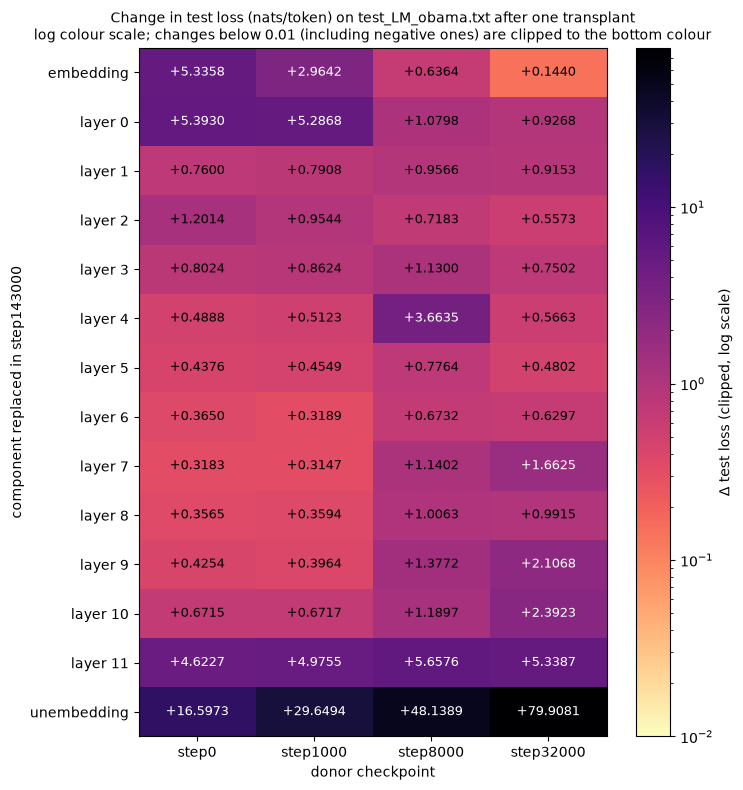

base test loss of intact step143000: 3.311874
exact change in test loss (transplanted - intact):
   component         step0      step1000      step8000     step32000
   embedding      5.335787      2.964201      0.636352      0.144035
     layer 0      5.393005      5.286799      1.079779      0.926832
     layer 1      0.760023      0.790784      0.956639      0.915284
     layer 2      1.201351      0.954401      0.718299      0.557325
     layer 3      0.802445      0.862358      1.129989      0.750186
     layer 4      0.488804      0.512275      3.663506      0.566339
     layer 5      0.437581      0.454908      0.776371      0.480200
     layer 6      0.364972      0.318886      0.673172      0.629672
     layer 7      0.318311      0.314739      1.140154      1.662468
     layer 8      0.356501      0.359393      1.006274      0.991502
     layer 9      0.425411      0.396446      1.377200      2.106825
    layer 10      0.671479      0.671746      1.189744      2.392313
    la

In [10]:
FLOOR = 1e-2
clipped = np.clip(delta, FLOOR, None)
fig, ax = plt.subplots(figsize=(7.5, 8))
image = ax.imshow(clipped, cmap="magma_r", norm=LogNorm(vmin=FLOOR, vmax=clipped.max()), aspect="auto")
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        ax.text(j, i, f"{delta[i, j]:+.4f}", ha="center", va="center", fontsize=9,
                color="white" if clipped[i, j] > 1.5 else "black")
ax.set_xticks(range(len(DONORS)), DONORS)
ax.set_yticks(range(len(COMPONENTS)), list(COMPONENTS))
ax.set_xlabel("donor checkpoint")
ax.set_ylabel(f"component replaced in {FINAL_STEP}")
ax.set_title("Change in test loss (nats/token) on test_LM_obama.txt after one transplant\n"
             f"log colour scale; changes below {FLOOR} (including negative ones) are clipped to the bottom colour",
             fontsize=10)
fig.colorbar(image, ax=ax, label="$\\Delta$ test loss (clipped, log scale)")
plt.tight_layout()
plt.show()

print(f"base test loss of intact {FINAL_STEP}: {base_loss:.6f}")
print("exact change in test loss (transplanted - intact):")
print(f"{'component':>12s}  " + "  ".join(f"{d:>12s}" for d in DONORS))
for i, name in enumerate(COMPONENTS):
    print(f"{name:>12s}  " + "  ".join(f"{delta[i, j]:12.6f}" for j in range(len(DONORS))))
print()
for i, name in enumerate(COMPONENTS):
    worst = int(np.argmax(delta[i]))
    monotone = all(delta[i, j] >= delta[i, j + 1] for j in range(len(DONORS) - 1))
    print(f"{name:>12s}: worst donor = {DONORS[worst]:>9s} ({delta[i, worst]:.4f}); "
          f"shrinks with every later donor: {monotone}")

### 3.3 additional measurements

The heatmap raises two questions that it cannot answer by itself: why is a random `step0` layer often *less* harmful than a half-trained one, and why does the unembedding get *worse* with later donors? The two cells below measure things that bear on those questions. They are extra experiments of my own, not part of the required component × donor grid.

**Measurement A: how strongly does a transplanted layer write into the residual stream?** For each donor layer placed in the final model, I record the size of what it adds, $\lVert \text{layer}(x) - x \rVert / \lVert x \rVert$, averaged over the tokens of the first test window. The same cell prints how similar the donor's embedding and unembedding rows are to the final model's (mean cosine similarity over the vocabulary), and their sizes.

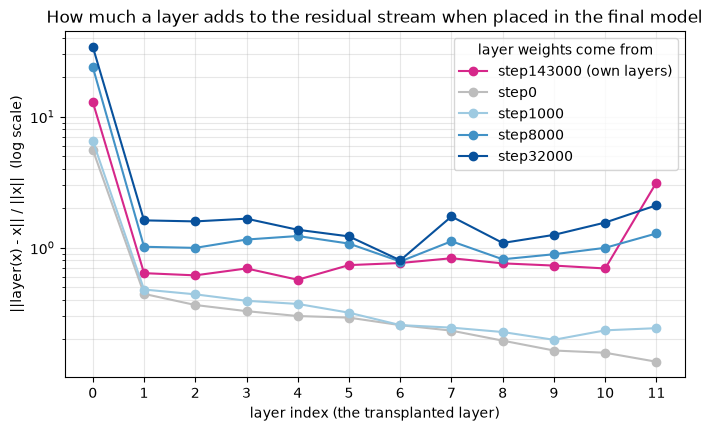

relative size of the layer's update, ||layer(x) - x|| / ||x||
           step143000       step0    step1000    step8000   step32000
  layer 0      12.943       5.592       6.524      23.910      34.187
  layer 1       0.639       0.444       0.479       1.015       1.615
  layer 2       0.614       0.365       0.440       0.996       1.586
  layer 3       0.694       0.327       0.393       1.153       1.664
  layer 4       0.569       0.301       0.372       1.227       1.369
  layer 5       0.736       0.292       0.319       1.074       1.219
  layer 6       0.763       0.256       0.256       0.784       0.800
  layer 7       0.830       0.232       0.245       1.119       1.729
  layer 8       0.759       0.195       0.227       0.815       1.086
  layer 9       0.729       0.164       0.198       0.891       1.252
 layer 10       0.693       0.158       0.234       0.997       1.555
 layer 11       3.142       0.135       0.243       1.284       2.107

donor weights compared with

     step0          0.008          0.035      0.632      0.632           1.000
  step1000          0.082          0.148      0.931      0.656           1.163
  step8000          0.182          0.503      1.303      1.166           1.783


 step32000          0.290          0.723      1.265      1.388           2.356
step143000          1.000          1.000      3.596      0.790           5.805


In [11]:
@torch.no_grad()
def relative_update(model, layer_index):
    "Mean over tokens of ||layer output - layer input|| / ||layer input|| on the first test window."
    seen = {}

    def hook(module, inputs, output):
        out = output[0] if isinstance(output, tuple) else output
        seen["ratio"] = ((out - inputs[0]).norm(dim=-1) / inputs[0].norm(dim=-1)).mean().item()

    handle = model.gpt_neox.layers[layer_index].register_forward_hook(hook)
    model(test_windows[0])
    handle.remove()
    return seen["ratio"]


LAYER_NAMES = [f"layer {i}" for i in range(12)]
update_size = {FINAL_STEP + " (own layers)": [relative_update(final_model, i) for i in range(12)]}
for donor in DONORS:
    sizes = []
    for i, name in enumerate(LAYER_NAMES):
        with transplanted(donor_states[donor], component_keys[name]) as patient:
            sizes.append(relative_update(patient, i))
    update_size[donor] = sizes

fig, ax = plt.subplots(figsize=(8, 4.5))
donor_colors = ["#bdbdbd", "#9ecae1", "#4292c6", "#08519c"]
for (label, sizes), color in zip(update_size.items(), ["#d6278a"] + donor_colors):
    ax.plot(range(12), sizes, marker="o", label=label, color=color)
ax.set_yscale("log")
ax.set_xticks(range(12))
ax.set_xlabel("layer index (the transplanted layer)")
ax.set_ylabel("||layer(x) - x|| / ||x||  (log scale)")
ax.set_title("How much a layer adds to the residual stream when placed in the final model")
ax.grid(alpha=0.3, which="both")
ax.legend(title="layer weights come from")
plt.show()

print("relative size of the layer's update, ||layer(x) - x|| / ||x||")
print(f"{'':>9s}  " + "  ".join(f"{label.split(' ')[0]:>10s}" for label in update_size))
for i, name in enumerate(LAYER_NAMES):
    print(f"{name:>9s}  " + "  ".join(f"{sizes[i]:10.3f}" for sizes in update_size.values()))

print()
print("donor weights compared with the final model's")
print(f"{'donor':>10s}  {'cos(W_U rows)':>13s}  {'cos(W_E rows)':>13s}  {'|W_U row|':>9s}  {'|W_E row|':>9s}  {'mean LN_f gain':>14s}")
cosine = torch.nn.functional.cosine_similarity
for step, state in [*donor_states.items(), (FINAL_STEP, final_state)]:
    print(f"{step:>10s}  "
          f"{cosine(state[UNEMBED_KEY], final_state[UNEMBED_KEY], dim=1).mean().item():13.3f}  "
          f"{cosine(state['gpt_neox.embed_in.weight'], final_state['gpt_neox.embed_in.weight'], dim=1).mean().item():13.3f}  "
          f"{state[UNEMBED_KEY].norm(dim=1).mean().item():9.3f}  "
          f"{state['gpt_neox.embed_in.weight'].norm(dim=1).mean().item():9.3f}  "
          f"{state['gpt_neox.final_layer_norm.weight'].abs().mean().item():14.3f}")

**Measurement B: is the unembedding damage about the unembedding alone, or about its partners?** The readout is $W_U\,\mathrm{LN}_f(h_{12})$, so $W_U$ works together with the final layer norm and with layer 11, which produces $h_{12}$. Here the donor's unembedding is transplanted alone (as in the heatmap), then together with the donor's $\mathrm{LN}_f$, then together with $\mathrm{LN}_f$ and layer 11.

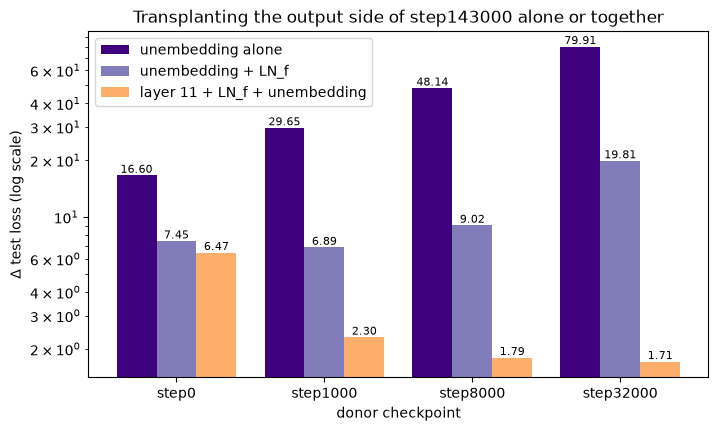

change in test loss (transplanted - intact):
            transplanted group       step0    step1000    step8000   step32000
             unembedding alone     16.5973     29.6494     48.1389     79.9081
            unembedding + LN_f      7.4481      6.8893      9.0208     19.8138
 layer 11 + LN_f + unembedding      6.4676      2.2995      1.7938      1.7074

size of the logits (std over the vocabulary, mean over positions) with the donor's unembedding alone:
                                     5.082       9.527      13.948      16.038


the intact step143000 model, for comparison: 99.057


In [12]:
LN_F_KEYS = [k for k in final_state if k.startswith("gpt_neox.final_layer_norm.")]
HEAD_GROUPS = {
    "unembedding alone": component_keys["unembedding"],
    "unembedding + LN_f": component_keys["unembedding"] + LN_F_KEYS,
    "layer 11 + LN_f + unembedding": component_keys["layer 11"] + LN_F_KEYS + component_keys["unembedding"],
}
@torch.no_grad()
def logit_spread(model):
    "Standard deviation of the logits over the vocabulary, averaged over the positions of the first test window."
    return model(test_windows[0]).logits[0].std(dim=-1).mean().item()


head_delta = np.zeros((len(HEAD_GROUPS), len(DONORS)))
spread_alone = []
for j, donor in enumerate(DONORS):
    for i, keys in enumerate(HEAD_GROUPS.values()):
        with transplanted(donor_states[donor], keys) as patient:
            head_delta[i, j] = test_loss(patient) - base_loss
            if i == 0:
                spread_alone.append(logit_spread(patient))
assert test_loss(final_model) == base_loss

fig, ax = plt.subplots(figsize=(8, 4.5))
width = 0.27
for i, name in enumerate(HEAD_GROUPS):
    bars = ax.bar(np.arange(len(DONORS)) + (i - 1) * width, head_delta[i], width, label=name,
                  color=["#3f007d", "#807dba", "#fdae6b"][i])
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_yscale("log")
ax.set_xticks(range(len(DONORS)), DONORS)
ax.set_xlabel("donor checkpoint")
ax.set_ylabel("$\\Delta$ test loss (log scale)")
ax.set_title(f"Transplanting the output side of {FINAL_STEP} alone or together")
ax.legend()
plt.show()

print("change in test loss (transplanted - intact):")
print(f"{'transplanted group':>30s}  " + "  ".join(f"{d:>10s}" for d in DONORS))
for i, name in enumerate(HEAD_GROUPS):
    print(f"{name:>30s}  " + "  ".join(f"{head_delta[i, j]:10.4f}" for j in range(len(DONORS))))
print()
print("size of the logits (std over the vocabulary, mean over positions) with the donor's unembedding alone:")
print(f"{'':>30s}  " + "  ".join(f"{spread:10.3f}" for spread in spread_alone))
print(f"the intact {FINAL_STEP} model, for comparison: {logit_spread(final_model):.3f}")

### 3.3 Answer

**For scale.** The intact final model has test loss 3.3119 (perplexity 27.4). A uniform guess over the vocabulary has loss 10.83, and the `step0` model on its own has 11.11. Every number below is a change in loss from 3.3119, read from the heatmap or from the two additional measurements.

### Which components can the model lose, and which are irreplaceable?

Replacing a component with its random `step0` version:

- **Can be lost at a small cost: the middle layers.** Layers 4 to 9 cost between +0.32 (layer 7) and +0.49 (layer 4). Layers 1, 3 and 10 cost +0.67 to +0.80 and layer 2 costs +1.20. None of this is free (+0.32 nats still multiplies perplexity by about 1.4), but the model keeps working: the loss stays near 3.6 to 4.5, far from the 10.83 of a uniform guess.
- **Irreplaceable: the two ends of the network.** The unembedding costs +16.60, which puts the loss at 19.9, *worse than guessing uniformly*. Layer 0 costs +5.39, the embedding +5.34 and layer 11 +4.62.

Measurement A explains why layers 0 and 11 behave like the embedding and unembedding and not like the other layers. In the final model, layer 0 adds an update 12.9 times the size of its input and layer 11 adds 3.14 times, while layers 1 to 10 each add between 0.57 and 0.83 times. So after layer 0 the residual stream is mostly layer 0's output (it is effectively part of the embedding), and layer 11 rewrites most of the stream just before the output head reads it. A middle layer makes a modest edit to a stream that also flows around it through the skip connection, and a random `step0` layer in its place adds only 0.16 to 0.44 times the input norm of noise, which the rest of the network tolerates.

### Does a later donor always hurt less? No.

The damage shrinks monotonically with later donors for only 3 of the 14 components (the last printout under the heatmap): the embedding (+5.34 → +2.96 → +0.64 → +0.14), layer 0 (+5.39 → +5.29 → +1.08 → +0.93) and layer 2 (+1.20 → +0.95 → +0.72 → +0.56).

**The embedding is the one component that is compatible with its younger self.** The Measurement A table shows why: the cosine similarity between a donor's embedding rows and the final ones climbs steadily (0.035, 0.148, 0.503, 0.723 for the four donors). The embedding settles early and then stays in roughly the same coordinates.

**Middle and late layers: a half-trained layer is often worse than a random one.**
- Layers 7, 9 and 10 are hurt *most* by the latest donor, `step32000`: +1.66, +2.11 and +2.39, against +0.32, +0.43 and +0.67 for random `step0` weights.
- For layers 1 and 3 to 11, `step0` is never the worst donor; the worst is `step8000` or `step32000`.
- Layer 4 has the largest single anomaly: +3.66 from `step8000`, against +0.49 from `step0` and +0.57 from `step32000`.

Measurement A gives a reason. A trained donor layer adds a much larger update than a random one: `step32000` layers 1 to 10 add between 0.80 and 1.73 times the input norm, more than the final model's own layers (0.57 to 0.83), while `step0` layers add 0.16 to 0.44. A random layer adds a small amount of noise. A layer from the middle of training adds a large, structured update in the coordinates of *its own* checkpoint, and the later layers of the final model then misread that update. A layer trained up to an earlier step is therefore a worse replacement than an untrained layer. The size of the update tracks the damage only loosely, though: for `step32000`, layer 6 has the smallest update (0.80) and small damage (+0.63), and layers 7, 9 and 10 have large updates (1.73, 1.25, 1.56) and the largest damage, but layer 3 has an update of 1.66 and only +0.75. And I do not have a full explanation for the layer 4 spike at `step8000`: its update there (1.23) is the largest among layers 1 to 10 for that donor, which is consistent with the same explanation but does not explain why this one layer stands out.

**The unembedding gets steadily worse with later donors:** +16.60, +29.65, +48.14, +79.91. Two measurements explain this.
- From the Measurement A table: the donor's unembedding rows are close to orthogonal to the final ones even at `step32000` (cosine 0.008, 0.082, 0.182, 0.290), so every donor reads the final model's last hidden state in the wrong basis and its logits point at the wrong tokens. What changes from donor to donor is the *size* of those wrong logits. Measurement B prints it: with the donor's unembedding in place, the standard deviation of the logits over the vocabulary is 5.082, 9.527, 13.948 and 16.038 for the four donors. The damage rises in the same order (+16.60, +29.65, +48.14, +79.91). Cross-entropy charges more for a wrong answer the further the wrong tokens are pushed above the true one, so wrong logits with a wider spread cost more. The donor rows also get longer during training (mean norm 0.632, 0.931, 1.303, 1.265), which accounts for part of the wider spread but not for the last step, where the norm does not grow. All four spreads are far below the intact model's 99.057, so the problem is not that the logits are large in absolute terms. It is that they are spread out along the wrong directions.
- Measurement B confirms that the problem is the pairing and not the unembedding itself. Transplanting the donor's $\mathrm{LN}_f$ along with its unembedding cuts the `step32000` damage from +79.91 to +19.81 (and `step0` from +16.60 to +7.45). Transplanting layer 11 as well cuts it to +1.71. With all three moved together, a later donor *is* better again: +6.47, +2.30, +1.79, +1.71. Moving three components together costs less than moving layer 11 alone (+5.34 from `step32000`).

### Summary

The layers of the final model are mostly *not* compatible with their younger selves. The embedding is, increasingly so. The output side (layer 11, $\mathrm{LN}_f$, unembedding) can be moved only as a unit, because its parts are fitted to each other and not to a fixed coordinate system. The middle layers change their coordinates during training: an earlier version of a middle layer is a worse replacement than random weights for most of them. This agrees with 3.2.2, where the middle layers move further away from the output basis as training goes on: both experiments say that the internal coordinates of the network keep changing during pretraining, even when the loss is almost flat (the `step32000` model on its own has loss 3.335, only 0.023 above the final model).